# Manuscript DAS Spectrogram Figures

DAS spectrograms (raw dB STFT) for three events. Figures are saved to `manuscript_figures/`.

- Humpback: 2025-11-14, file `09.33.00` UTC (onyx haro-fs)
- Bigg's killer whale: 2026-01-02, file `23.43.00` UTC (haro_fs)
- SRKW (J pod): 2026-01-23, file `21.37.00` UTC (haro_fs)

In [1]:
import os
import h5py
import numpy as np
import scipy.signal as sp
from scipy.signal import stft, detrend
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from das_functions import get_h5_metadata, load_data, preprocess

OUT_DIR = "manuscript_figures"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- loop geometry (m) ----
dx = 3.19
LOOPS = {
    1: (120, 140), 2: (144, 203), 3: (271, 296), 4: (443, 465), 5: (630, 660),
    6: (855, 887), 7: (1091, 1123), 8: (1659, 1722), 9: (1821, 1879),
}

print("setup ready")

setup ready


In [2]:
def load_event(fdir, fname):
    """Load one 60 s file, detrended and 250 Hz high-passed. Returns (data, fs)."""
    meta = get_h5_metadata(os.path.join(fdir, fname))
    fs = meta['fs']
    data_raw, _ = load_data(fdir, [fname])
    data = preprocess(data_raw, fs, lowcut=250)   # detrend + 250Hz highpass
    return data, fs

def stack_range(data, m0, m1):
    """Mean-stack all channels whose optical distance falls in [m0, m1) meters."""
    c0, c1 = int(m0 / dx), int(m1 / dx)
    return np.mean(data[:, c0:c1], axis=1), (c0, c1)

def stack_loop(data, loop_id):
    m0, m1 = LOOPS[loop_id]
    return stack_range(data, m0, m1)

def plot_manuscript_spectrogram(stacked, fs, t_start, t_end, vmin, vmax, y_max=2500,
                                 title=None, save_name=None, nperseg=512, noverlap_frac=0.8):
    """Raw dB STFT spectrogram. t_start/t_end are seconds from file start."""
    noverlap = int(nperseg * noverlap_frac)
    f, t_spec, Zxx = stft(stacked, fs=fs, nperseg=nperseg, noverlap=noverlap)

    mask = (t_spec >= t_start) & (t_spec <= t_end)
    t_plot = t_spec[mask] - t_start
    Z_plot = Zxx[:, mask]
    Sxx_dB = 20 * np.log10(np.abs(Z_plot) + 1e-12)

    print(f"  Sxx_dB range: min={Sxx_dB.min():.1f}  p50={np.median(Sxx_dB):.1f}  "
          f"p99={np.percentile(Sxx_dB, 99):.1f}  max={Sxx_dB.max():.1f}  "
          f"(vmin/vmax used: {vmin}/{vmax})")

    plt.rcParams.update({'font.size': 25})
    fig = plt.figure(figsize=(10, 5), dpi=300)

    pcm = plt.pcolormesh(t_plot, f, Sxx_dB, shading='gouraud', cmap='plasma', vmin=vmin, vmax=vmax)
    plt.colorbar(pcm, label=r'Amplitude [dB re $1\,\mathrm{n}\epsilon$]', pad=0.01)

    plt.xlim(0, t_end - t_start)
    plt.xticks(np.arange(0, (t_end - t_start) + 1, 5))
    ax = plt.gca()
    ax.set_xticks(np.arange(0, (t_end - t_start) + 1, 1), minor=True)
    ax.tick_params(axis='x', which='minor', length=4)
    ax.tick_params(axis='x', which='major', length=7)

    plt.ylim(0, y_max)
    yticks = np.arange(0, y_max + 1, 500)
    plt.yticks(yticks, labels=yticks / 1000)
    ax.set_yticks(np.arange(0, y_max + 1, 100), minor=True)
    ax.tick_params(axis='y', which='minor', length=3)
    ax.tick_params(axis='y', which='major', length=6)

    plt.ylabel('Frequency [kHz]')
    plt.xlabel('Time [s]')
    if title:
        plt.title(title, fontsize=16)

    plt.tight_layout()
    if save_name:
        path = os.path.join(OUT_DIR, save_name)
        fig.savefig(path, format='jpeg', dpi=300)
        print(f"  saved {path}")
    plt.show()

print("helpers ready")

helpers ready


## Figure 5

- (b) Humpback, loop 1, 09:33:45–09:34:00 UTC
- (d) Bigg's, loop 1, 23:43:12–23:43:27 UTC
- (f) SRKW, loop 2, 21:37:00–21:37:15 UTC

In [3]:
# ---- load the three Figure 5 events ----
data_humpback, fs_humpback = load_event('/mnt/nas_das4orcas_onyx/haro-fs/', 'decimator_2025-11-14_09.33.00_UTC_049649.h5')
data_biggs, fs_biggs = load_event('/mnt/haro_fs/', 'decimator_2026-01-02_23.43.00_UTC_097029.h5')
data_srkw, fs_srkw = load_event('/mnt/haro_fs/', 'decimator_2026-01-23_21.37.00_UTC_126890.h5')

print(f"humpback: {data_humpback.shape}, fs={fs_humpback}")
print(f"biggs:    {data_biggs.shape}, fs={fs_biggs}")
print(f"srkw:     {data_srkw.shape}, fs={fs_srkw}")

humpback: (300000, 1257), fs=5000.0
biggs:    (300000, 1257), fs=5000.0
srkw:     (300000, 1257), fs=5000.0


loop 1 channels: (37, 43)
  Sxx_dB range: min=-224.5  p50=-77.6  p99=-67.3  max=-50.5  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure5b.jpeg


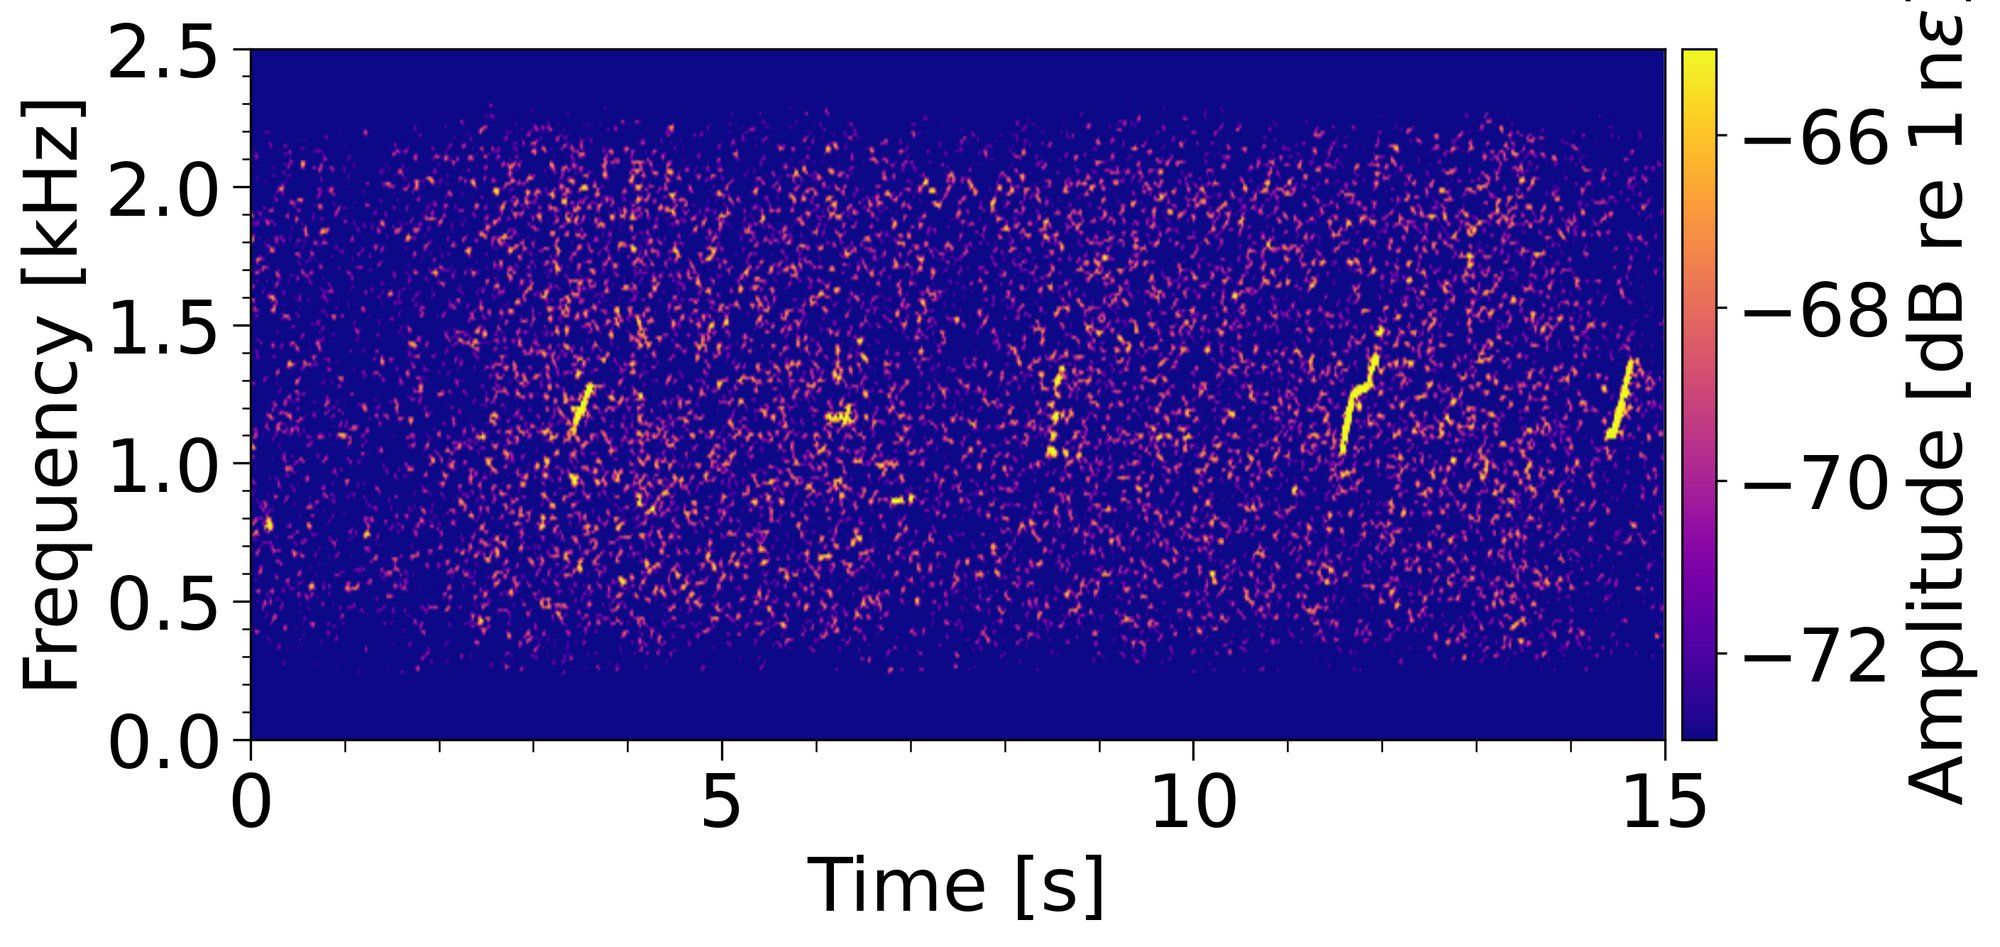

In [4]:
# Figure 5b -- Humpback, loop 1, 09:33:45-09:34:00 (t=45-60 within the file)
stacked, chans = stack_loop(data_humpback, 1)
print(f"loop 1 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_humpback, t_start=45, t_end=60, vmin=-73, vmax=-65,
                             save_name="Figure5b.jpeg")

loop 1 channels: (37, 43)
  Sxx_dB range: min=-215.8  p50=-80.3  p99=-70.0  max=-56.8  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure5d.jpeg


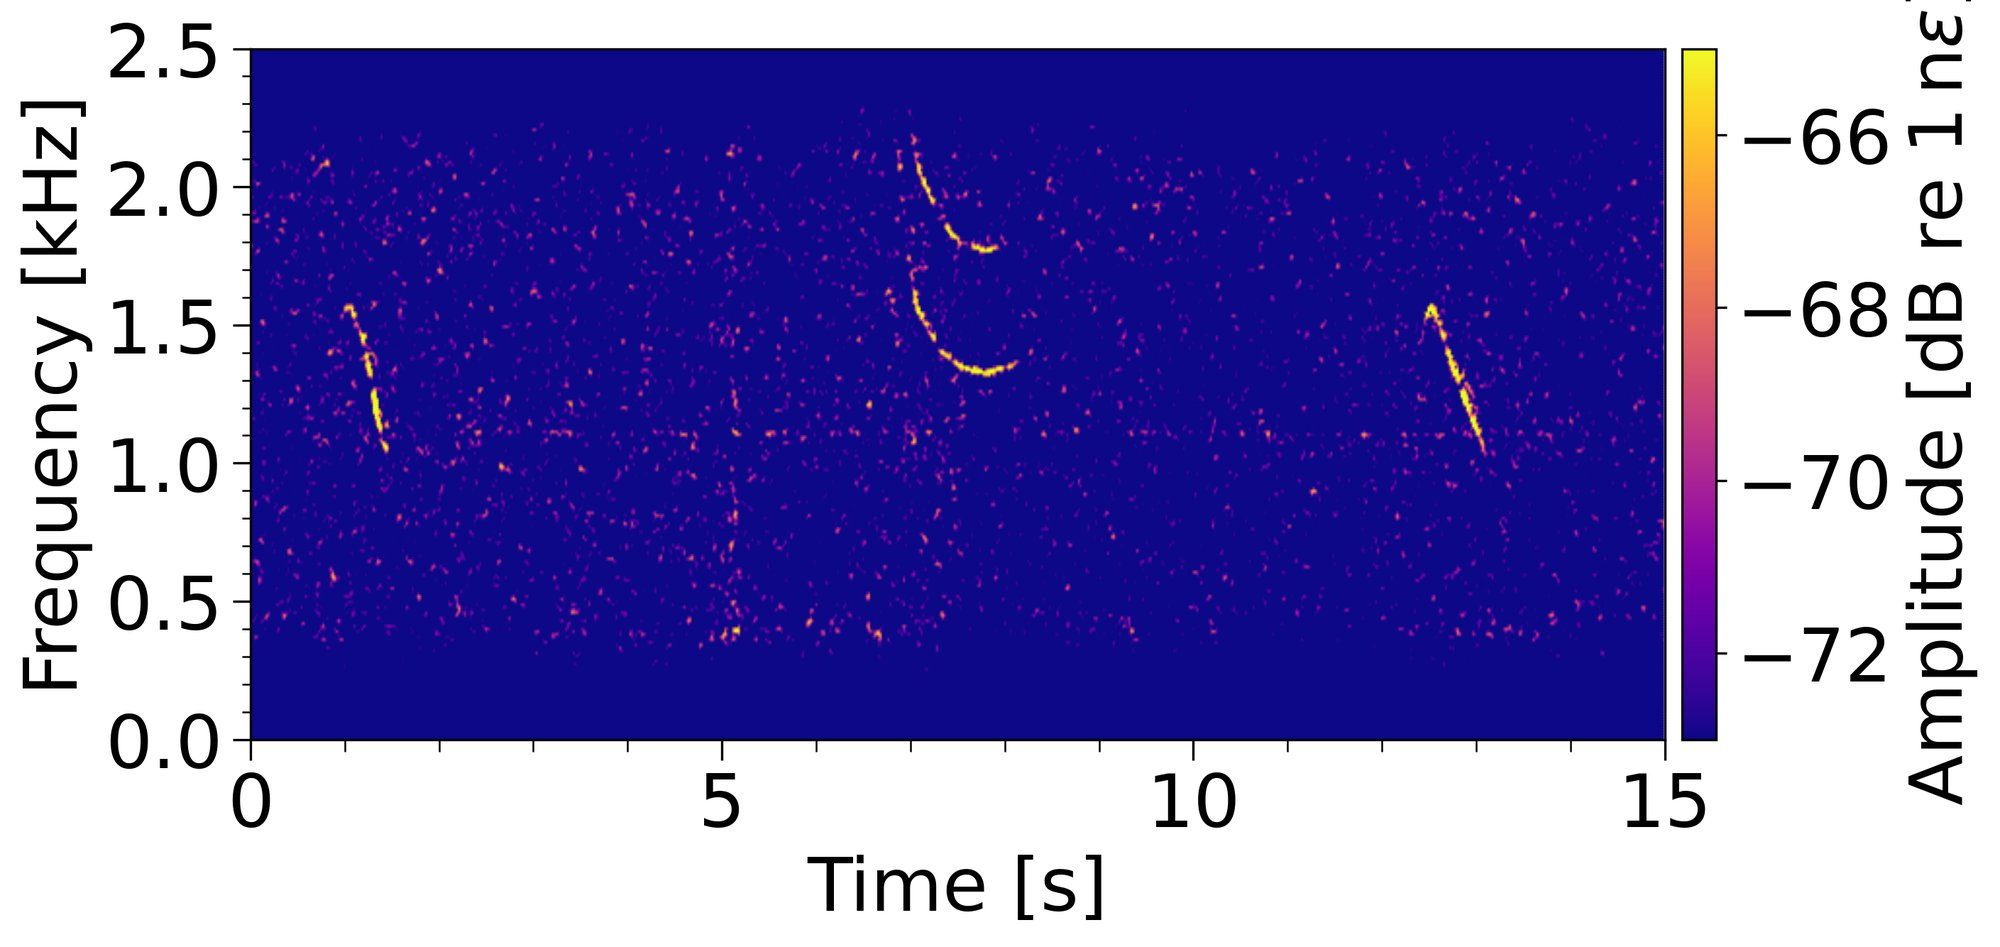

In [5]:
# Figure 5d -- Bigg's, loop 1, 23:43:12-23:43:27 (t=12-27 within the file)
stacked, chans = stack_loop(data_biggs, 1)
print(f"loop 1 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_biggs, t_start=12, t_end=27, vmin=-73, vmax=-65,
                             save_name="Figure5d.jpeg")

loop 2 channels: (45, 63)
  Sxx_dB range: min=-223.9  p50=-81.8  p99=-69.3  max=-48.5  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure5f.jpeg


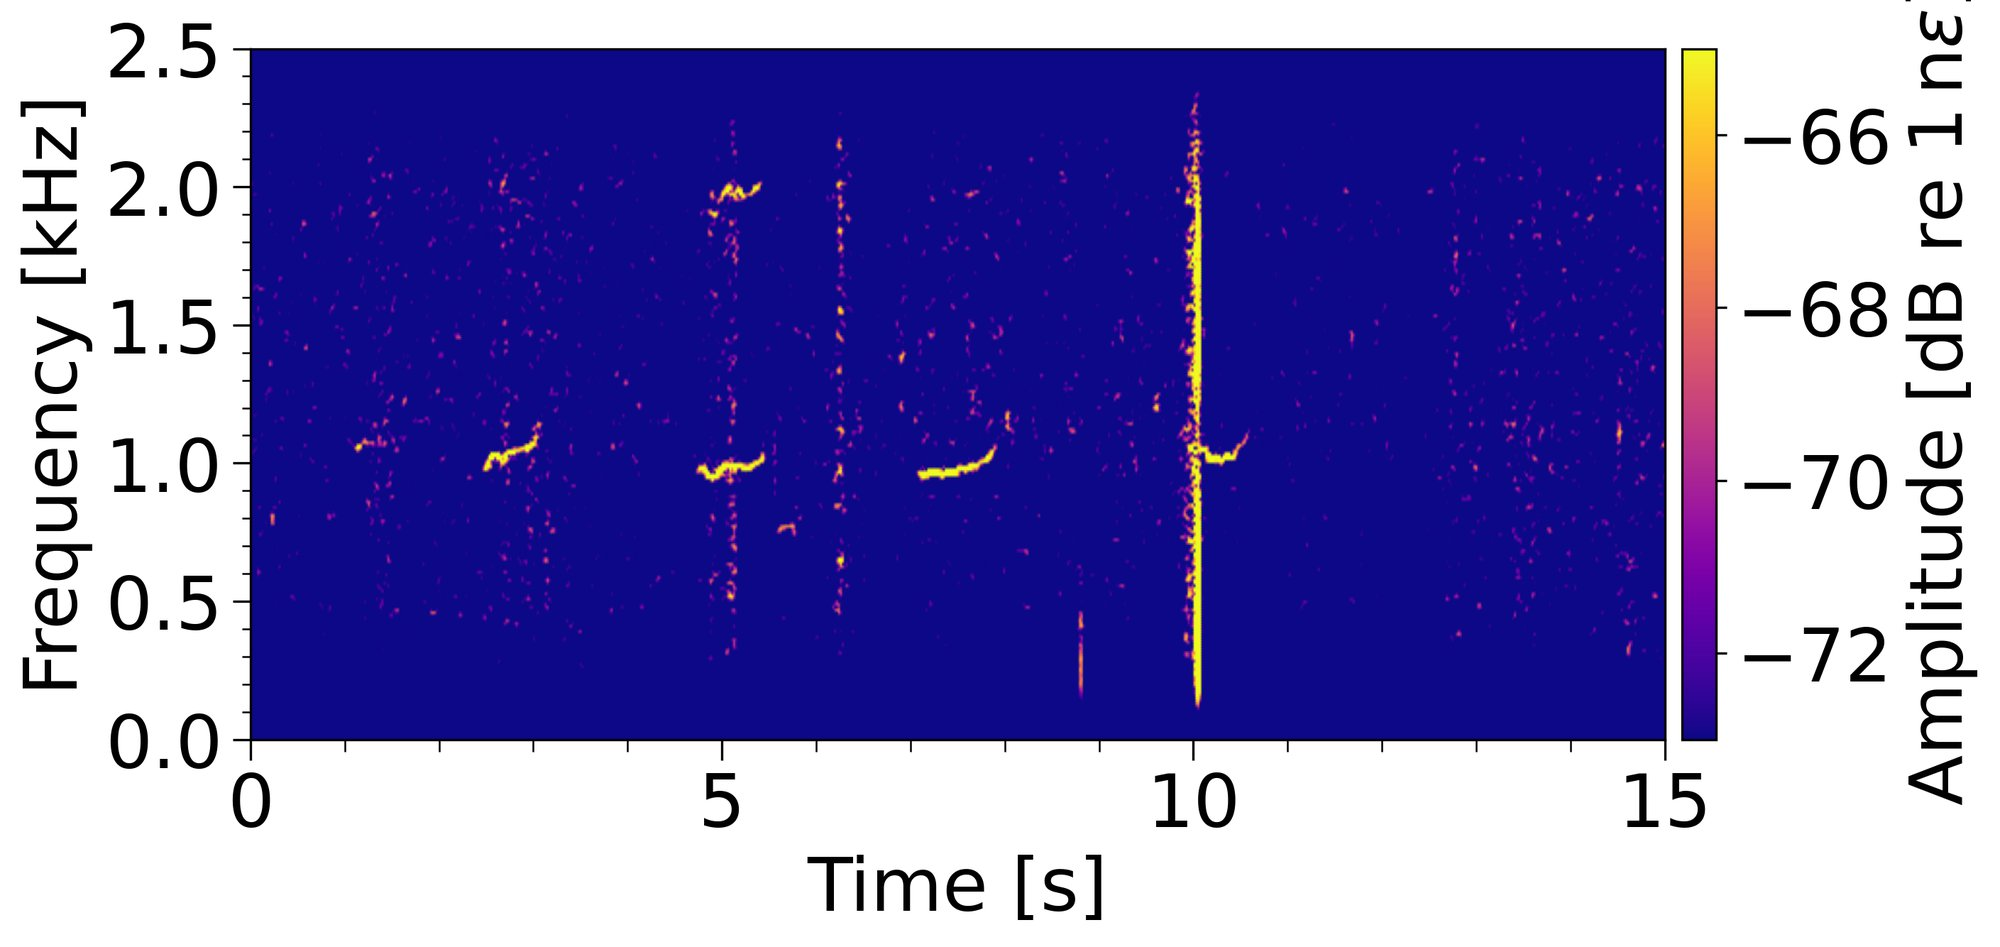

In [6]:
# Figure 5f -- SRKW, loop 2, 21:37:00-21:37:15 (t=0-15 within the file)
stacked, chans = stack_loop(data_srkw, 2)
print(f"loop 2 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_srkw, t_start=0, t_end=15, vmin=-73, vmax=-65,
                             save_name="Figure5f.jpeg")

## Figure 6

- (a) Humpback, loop 8, same window as 5b, full frequency range (multipath)
- (b) Bigg's, loop 3, same window as 5d, lower frequencies
- (c) Humpback, loop 8, six minutes later (09:39:02–09:39:17 UTC)

loop 8 channels: (520, 539)
  Sxx_dB range: min=-232.5  p50=-81.6  p99=-70.6  max=-54.8  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure6a.jpeg


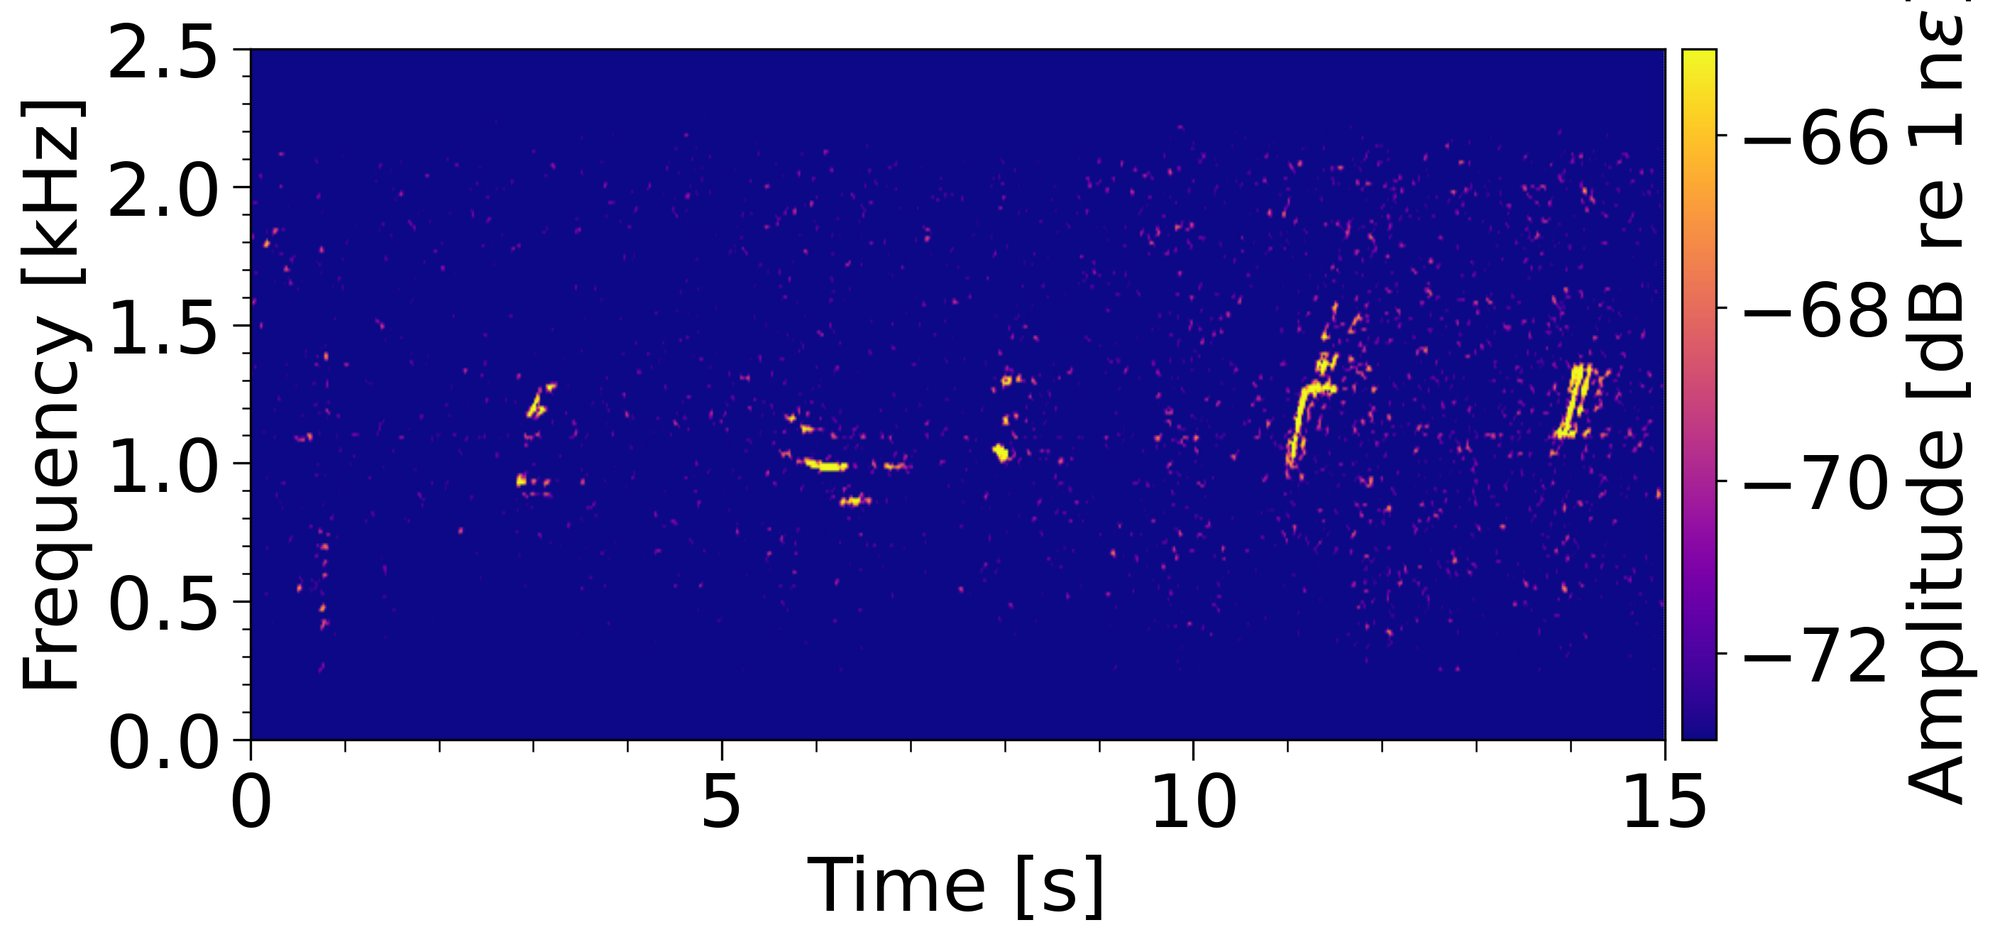

In [7]:
# Figure 6a -- Humpback, loop 8, same window as Fig 5b, full 0-2500Hz range
stacked, chans = stack_loop(data_humpback, 8)
print(f"loop 8 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_humpback, t_start=45, t_end=60, vmin=-73, vmax=-65, y_max=2500,
                             save_name="Figure6a.jpeg")

loop 3 channels: (84, 92)
  Sxx_dB range: min=-212.7  p50=-78.1  p99=-67.3  max=-56.6  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure6b.jpeg


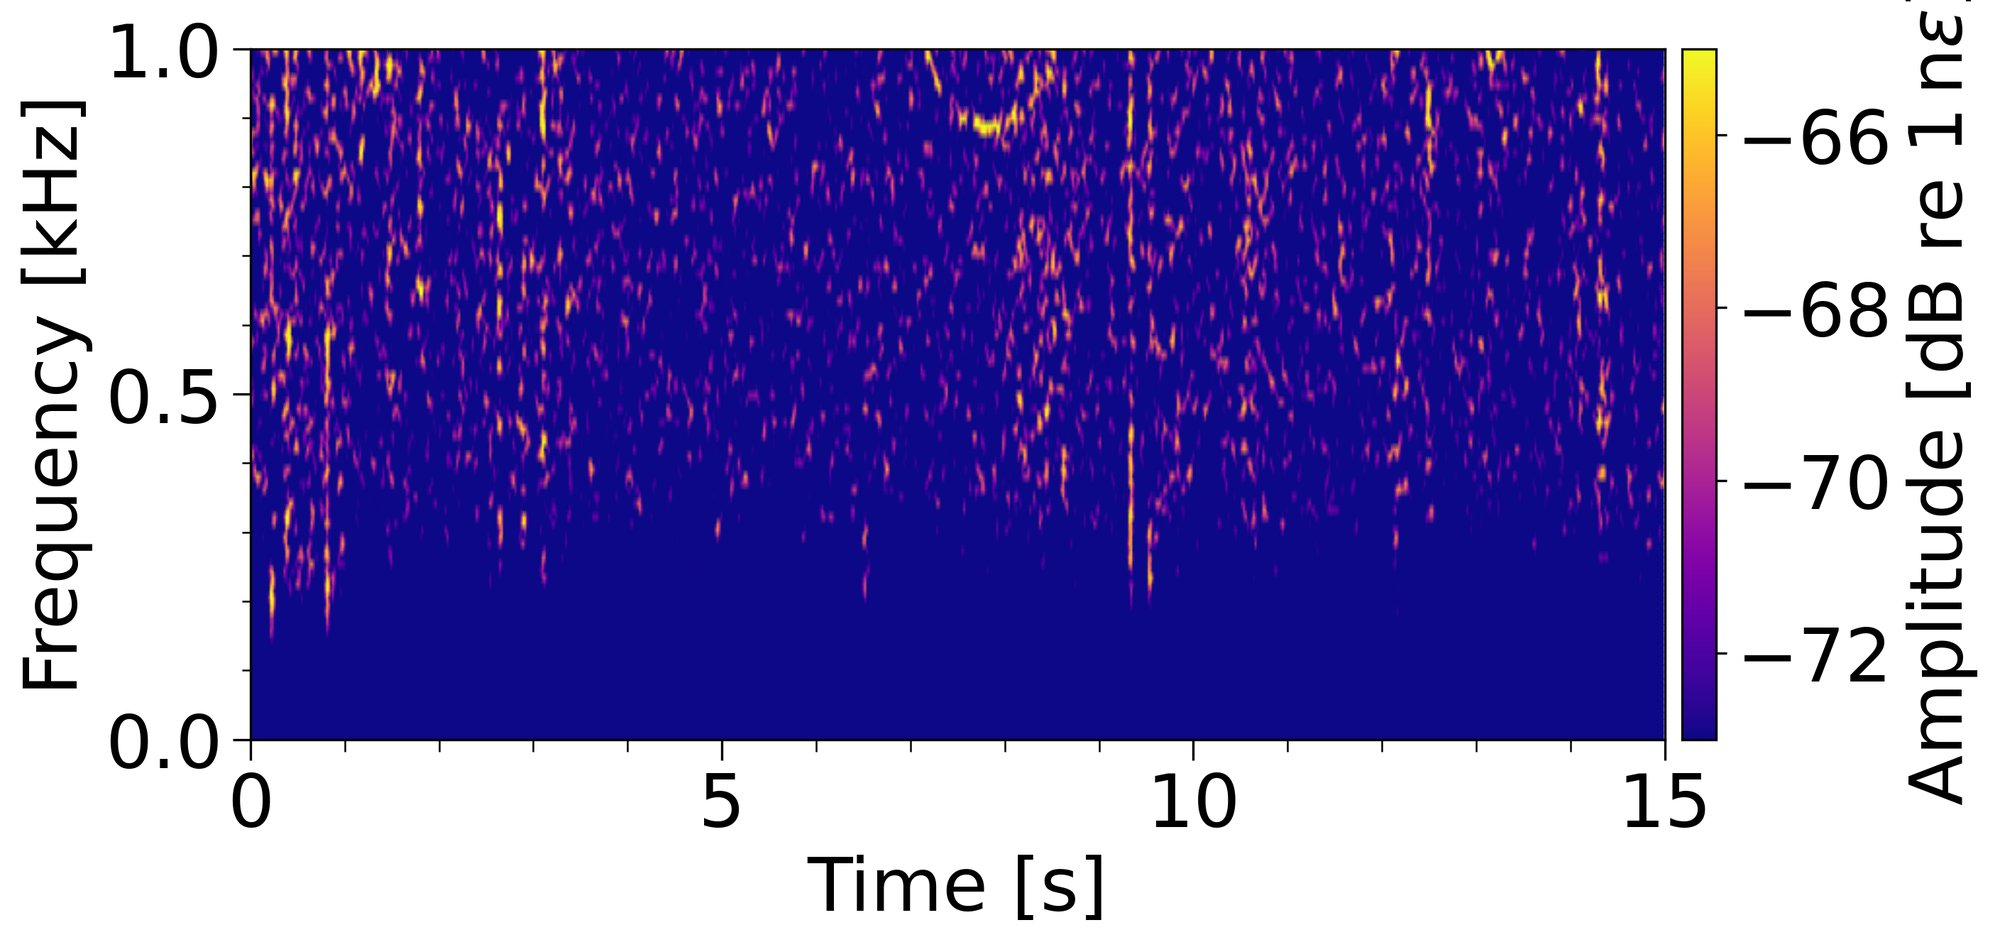

In [8]:
# Figure 6b -- Bigg's, loop 3, same window as Fig 5d, lower frequency range
stacked, chans = stack_loop(data_biggs, 3)
print(f"loop 3 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_biggs, t_start=12, t_end=27, vmin=-73, vmax=-65, y_max=1000,
                             save_name="Figure6b.jpeg")

humpback +6min: (300000, 1257), fs=5000.0
loop 8 channels: (520, 539)
  Sxx_dB range: min=-221.9  p50=-80.9  p99=-68.4  max=-51.4  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure6c.jpeg


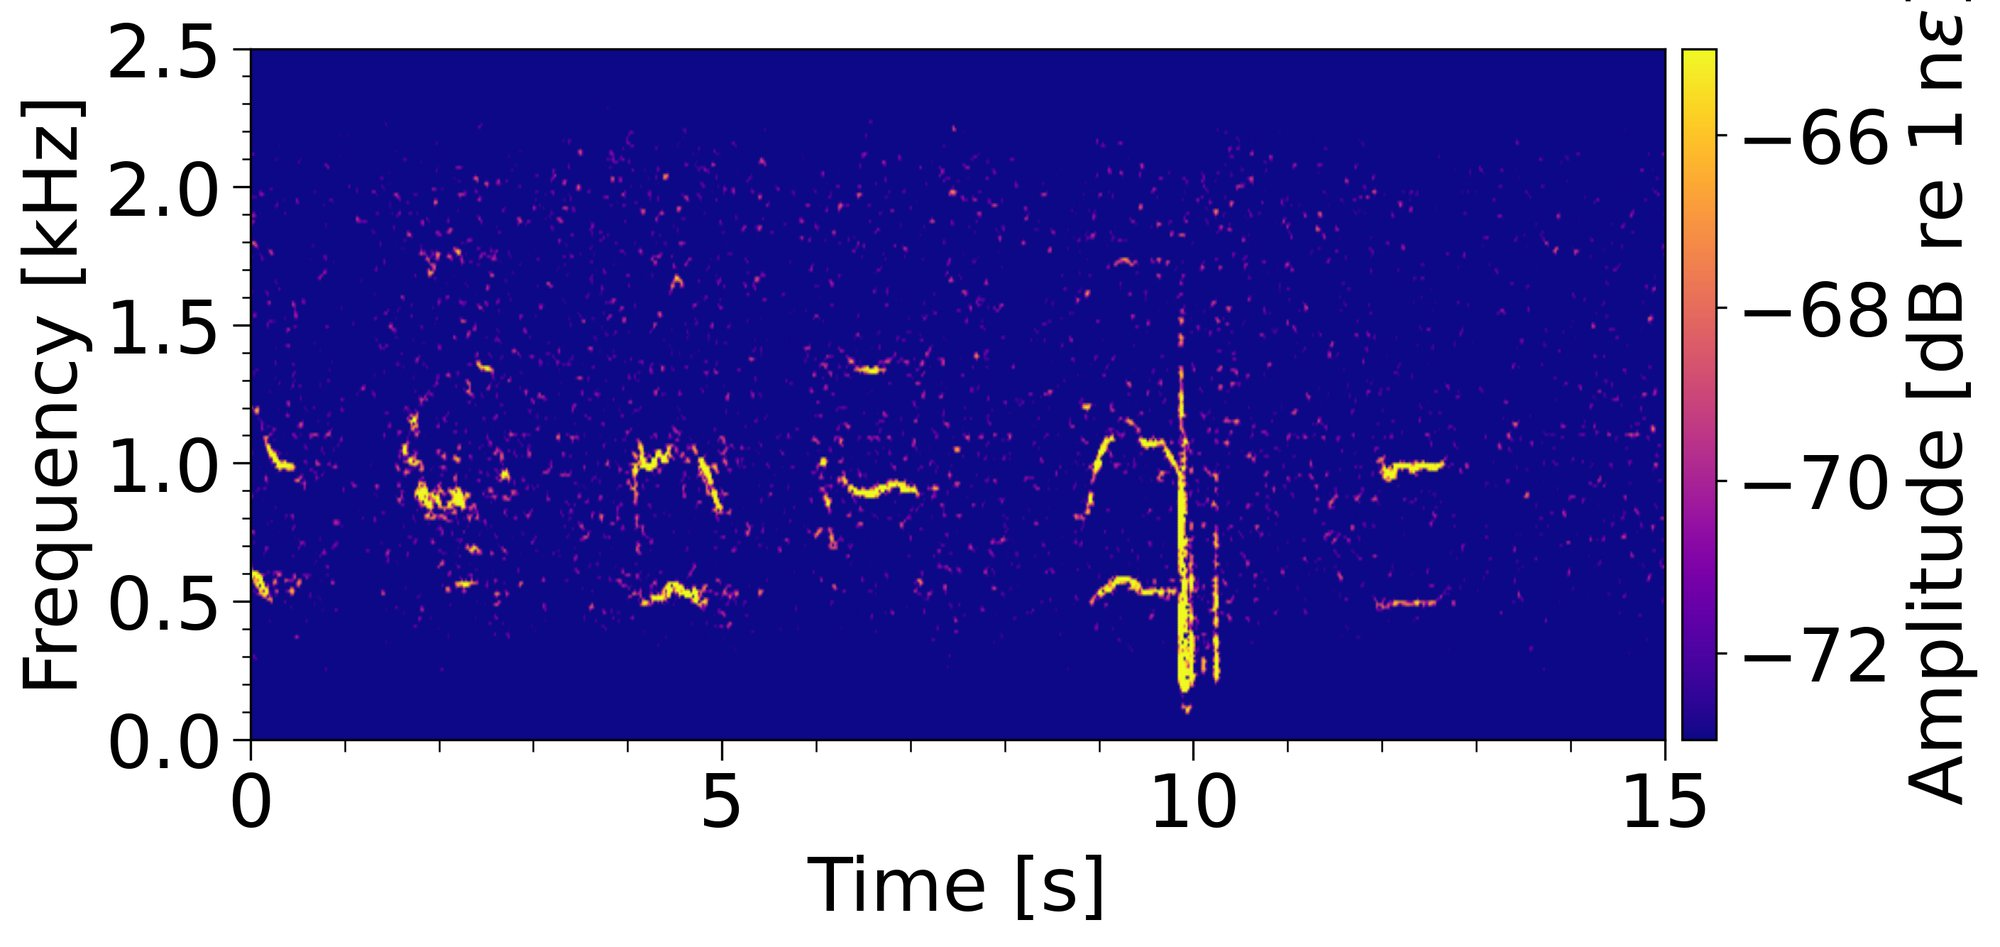

In [9]:
# Figure 6c -- Humpback, loop 8, SAME DAY as Fig 5b but 6 minutes later
# file 09.39.00, t=2-17 s -> 09:39:02-09:39:17 UTC
data_humpback_p6, fs_humpback_p6 = load_event(
    '/mnt/nas_das4orcas_onyx/haro-fs/', 'decimator_2025-11-14_09.39.00_UTC_049655.h5')
print(f"humpback +6min: {data_humpback_p6.shape}, fs={fs_humpback_p6}")

stacked, chans = stack_loop(data_humpback_p6, 8)
print(f"loop 8 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_humpback_p6, t_start=2, t_end=17, vmin=-73, vmax=-65,
                             save_name="Figure6c.jpeg")

## Figure 7

Humpback, full minute 09:33–09:34 UTC.

- (a) Straight-section stack, 485–505 m (6 channels)
- (b) Loop 5, 630–660 m

485-505m channels: (152, 158) (6 channels)
  Sxx_dB range: min=-229.4  p50=-77.5  p99=-64.0  max=-49.2  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure7a.jpeg


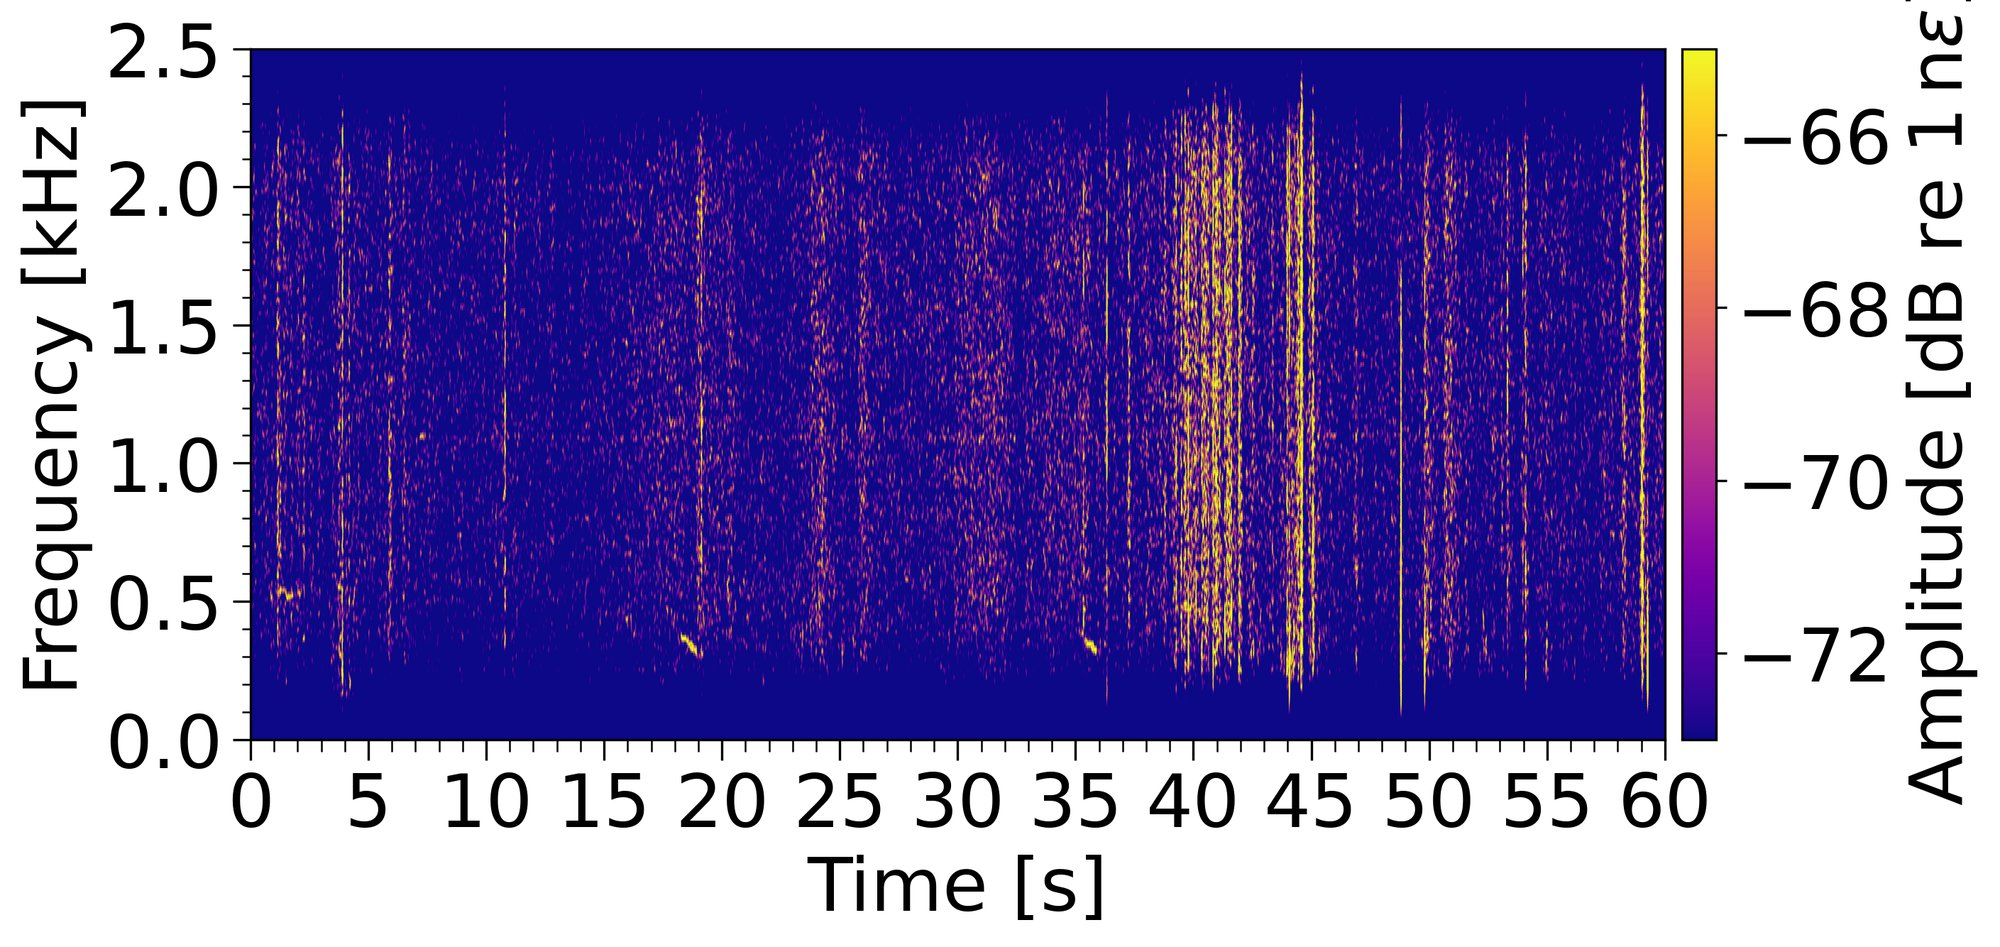

In [10]:
# Figure 7a -- Humpback, custom straight-section stack, 485-505m (6 channels)
stacked, chans = stack_range(data_humpback, 485, 505)
print(f"485-505m channels: {chans} ({chans[1]-chans[0]} channels)")
plot_manuscript_spectrogram(stacked, fs_humpback, t_start=0, t_end=60, vmin=-73, vmax=-65,
                             save_name="Figure7a.jpeg")

loop 5 channels: (197, 206)
  Sxx_dB range: min=-230.1  p50=-80.1  p99=-70.0  max=-54.7  (vmin/vmax used: -73/-65)


  saved manuscript_figures/Figure7b.jpeg


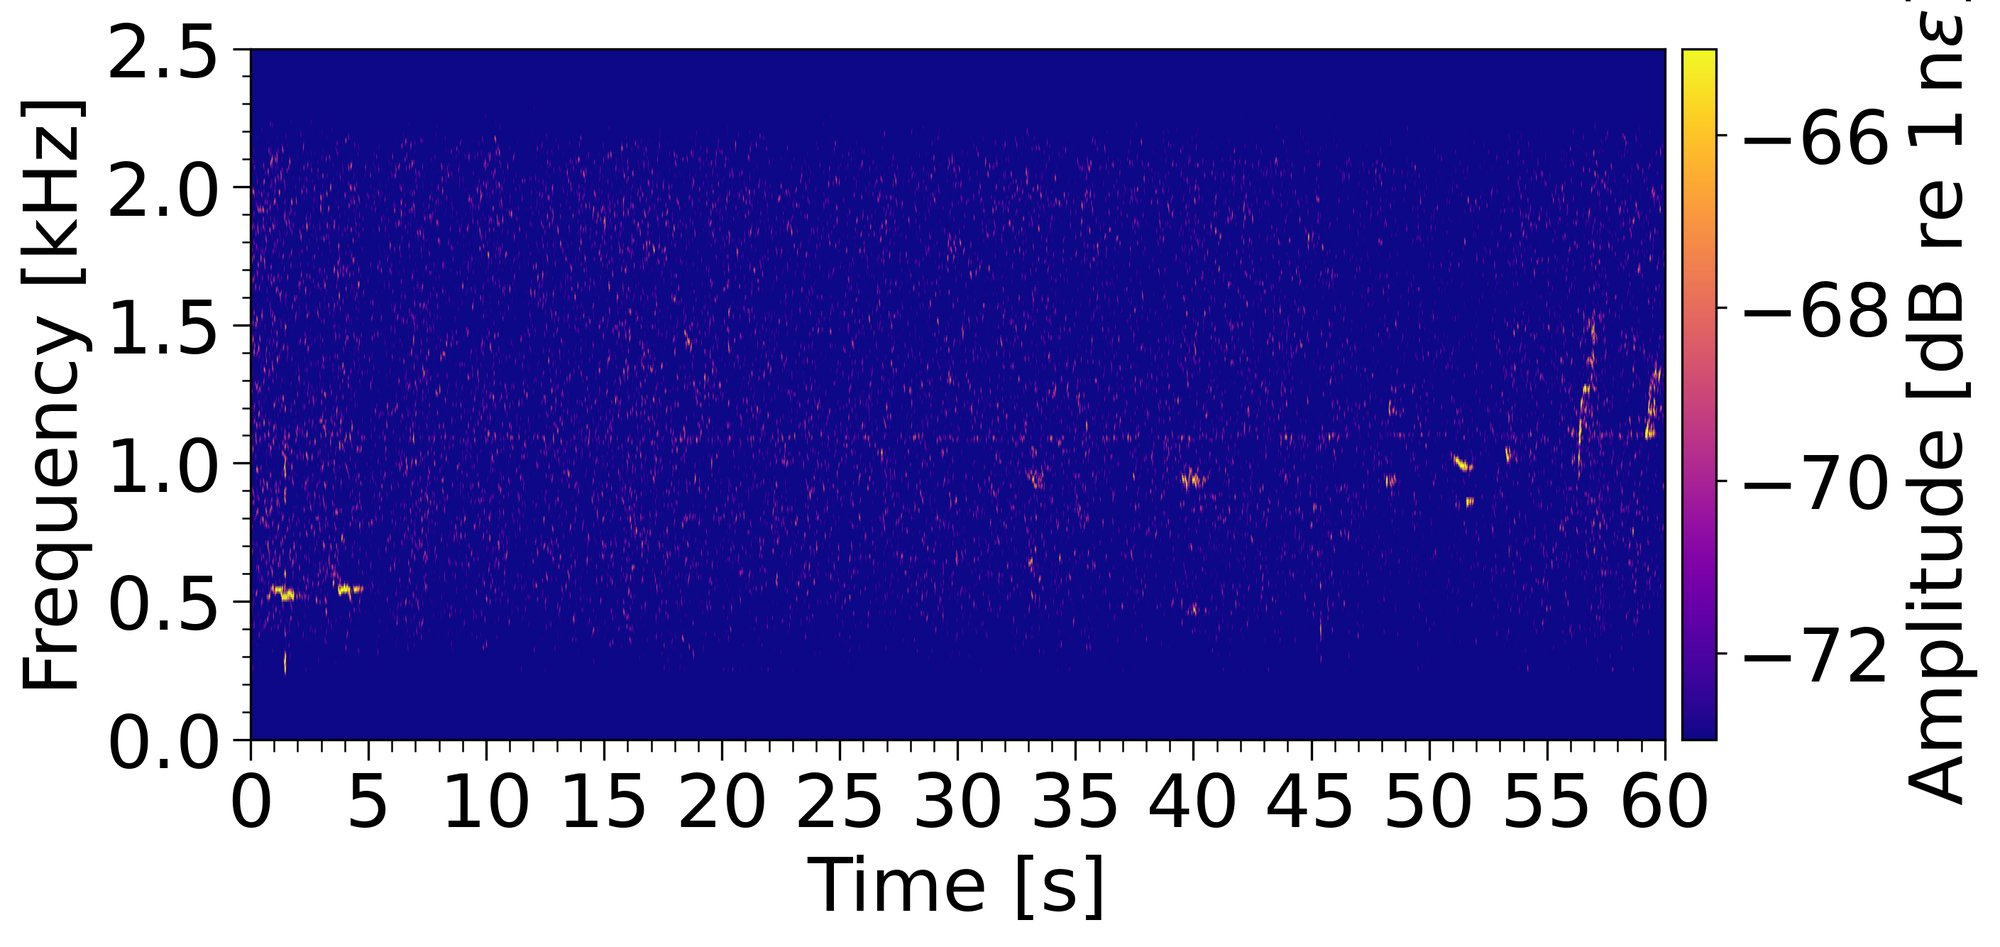

In [11]:
# Figure 7b -- Humpback, loop 5 (630-660m)
stacked, chans = stack_loop(data_humpback, 5)
print(f"loop 5 channels: {chans}")
plot_manuscript_spectrogram(stacked, fs_humpback, t_start=0, t_end=60, vmin=-73, vmax=-65,
                             save_name="Figure7b.jpeg")